# Training Effectiveness Analysis Using Machine Learning
**Case Study No. 88 — B.Tech CSE Semester V**

This notebook contains the complete end-to-end ML pipeline:
1. Data Loading & Exploration
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Model Training & Evaluation
5. Feature Importance
6. Error Analysis


In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully.")


All libraries imported successfully.


## 1. Data Loading & Initial Exploration

**Dataset:** IBM HR Analytics Employee Attrition & Performance  
**Source:** Kaggle (via GitHub mirror)  
**Records:** 1470 | **Features:** 35


In [2]:
df = pd.read_csv('../data/training_data.csv')
print(f"Dataset Shape: {df.shape}")
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
df.head()


Dataset Shape: (1470, 35)
Missing Values: 0
Duplicate Rows: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
df.describe()


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## 2. Target Variable Construction

The dataset does not have a direct "Post-Training Outcome" column.  
We use `PerformanceRating` as a proxy:
- **4 (Outstanding)** → `Successful` (1)
- **3 (Excellent / baseline)** → `Needs Improvement` (0)

> **Note:** `PercentSalaryHike` is perfectly correlated with `PerformanceRating` in this synthetic dataset and is dropped to **prevent data leakage**.


In [5]:
print("PerformanceRating distribution:")
print(df['PerformanceRating'].value_counts())

# Create binary target
df['Outcome'] = df['PerformanceRating'].apply(lambda x: 1 if x == 4 else 0)
print(f"\nOutcome distribution:\n{df['Outcome'].value_counts()}")
print(f"\nClass imbalance ratio: {df['Outcome'].value_counts()[0] / df['Outcome'].value_counts()[1]:.2f}:1")


PerformanceRating distribution:
PerformanceRating
3    1244
4     226
Name: count, dtype: int64

Outcome distribution:
Outcome
0    1244
1     226
Name: count, dtype: int64

Class imbalance ratio: 5.50:1


## 3. Exploratory Data Analysis (EDA)


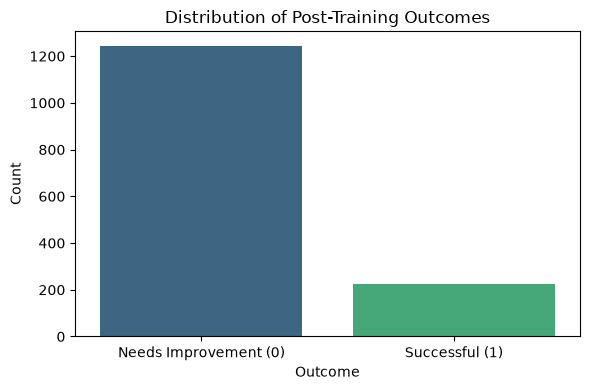

In [6]:
# 1. Outcome Distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='Outcome', data=df, palette='viridis', ax=ax)
ax.set_xticklabels(['Needs Improvement (0)', 'Successful (1)'])
ax.set_title('Distribution of Post-Training Outcomes')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()


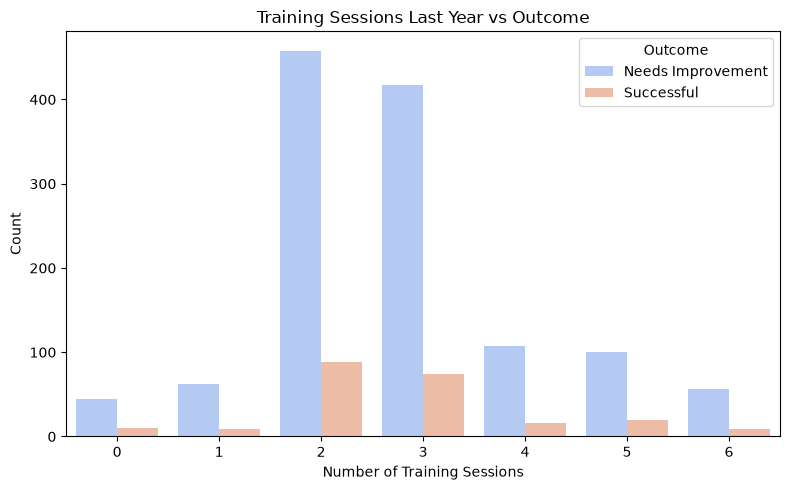

In [7]:
# 2. Training Times Last Year vs Outcome
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(x='TrainingTimesLastYear', hue='Outcome', data=df, palette='coolwarm', ax=ax)
ax.set_title('Training Sessions Last Year vs Outcome')
ax.set_xlabel('Number of Training Sessions')
ax.set_ylabel('Count')
ax.legend(title='Outcome', labels=['Needs Improvement', 'Successful'])
plt.tight_layout()
plt.show()


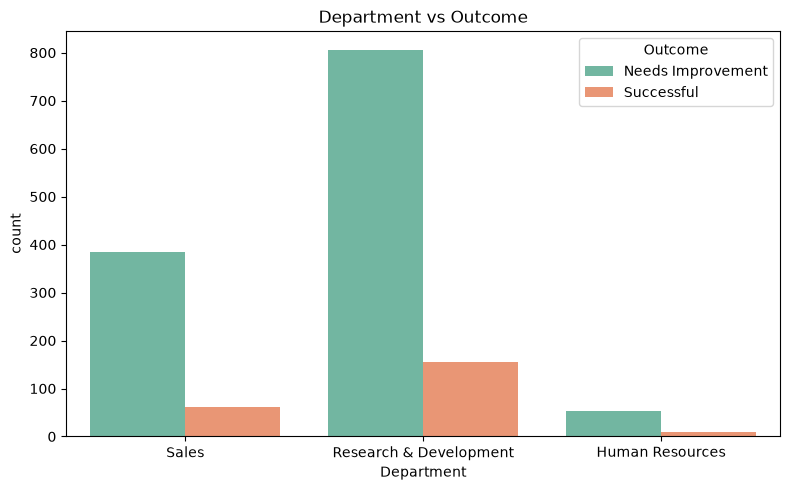

In [8]:
# 3. Department vs Outcome
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(x='Department', hue='Outcome', data=df, palette='Set2', ax=ax)
ax.set_title('Department vs Outcome')
ax.legend(title='Outcome', labels=['Needs Improvement', 'Successful'])
plt.tight_layout()
plt.show()


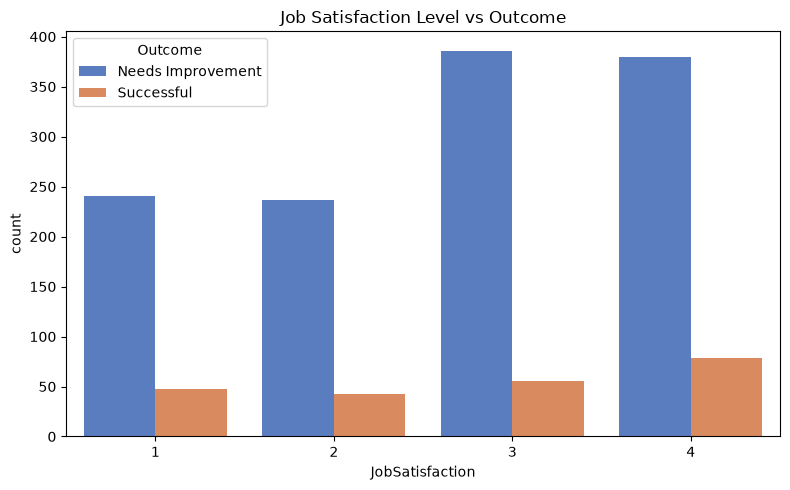

In [9]:
# 4. Job Satisfaction vs Outcome
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(x='JobSatisfaction', hue='Outcome', data=df, palette='muted', ax=ax)
ax.set_title('Job Satisfaction Level vs Outcome')
ax.legend(title='Outcome', labels=['Needs Improvement', 'Successful'])
plt.tight_layout()
plt.show()


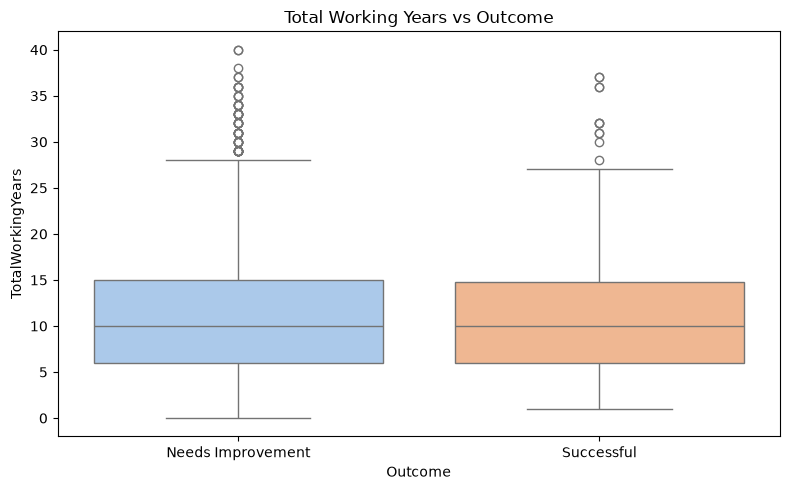

In [10]:
# 5. Total Working Years vs Outcome
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(x='Outcome', y='TotalWorkingYears', data=df, palette='pastel', ax=ax)
ax.set_xticklabels(['Needs Improvement', 'Successful'])
ax.set_title('Total Working Years vs Outcome')
plt.tight_layout()
plt.show()


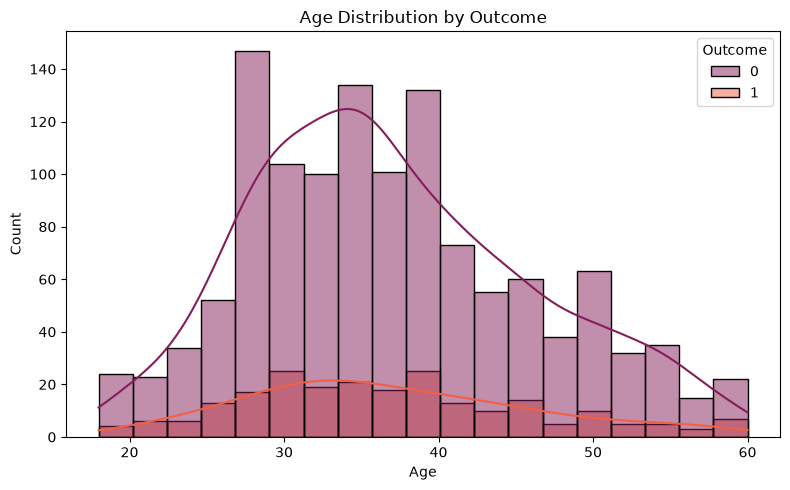

In [11]:
# 6. Age Distribution by Outcome
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Outcome', kde=True, palette='rocket', ax=ax)
ax.set_title('Age Distribution by Outcome')
plt.tight_layout()
plt.show()


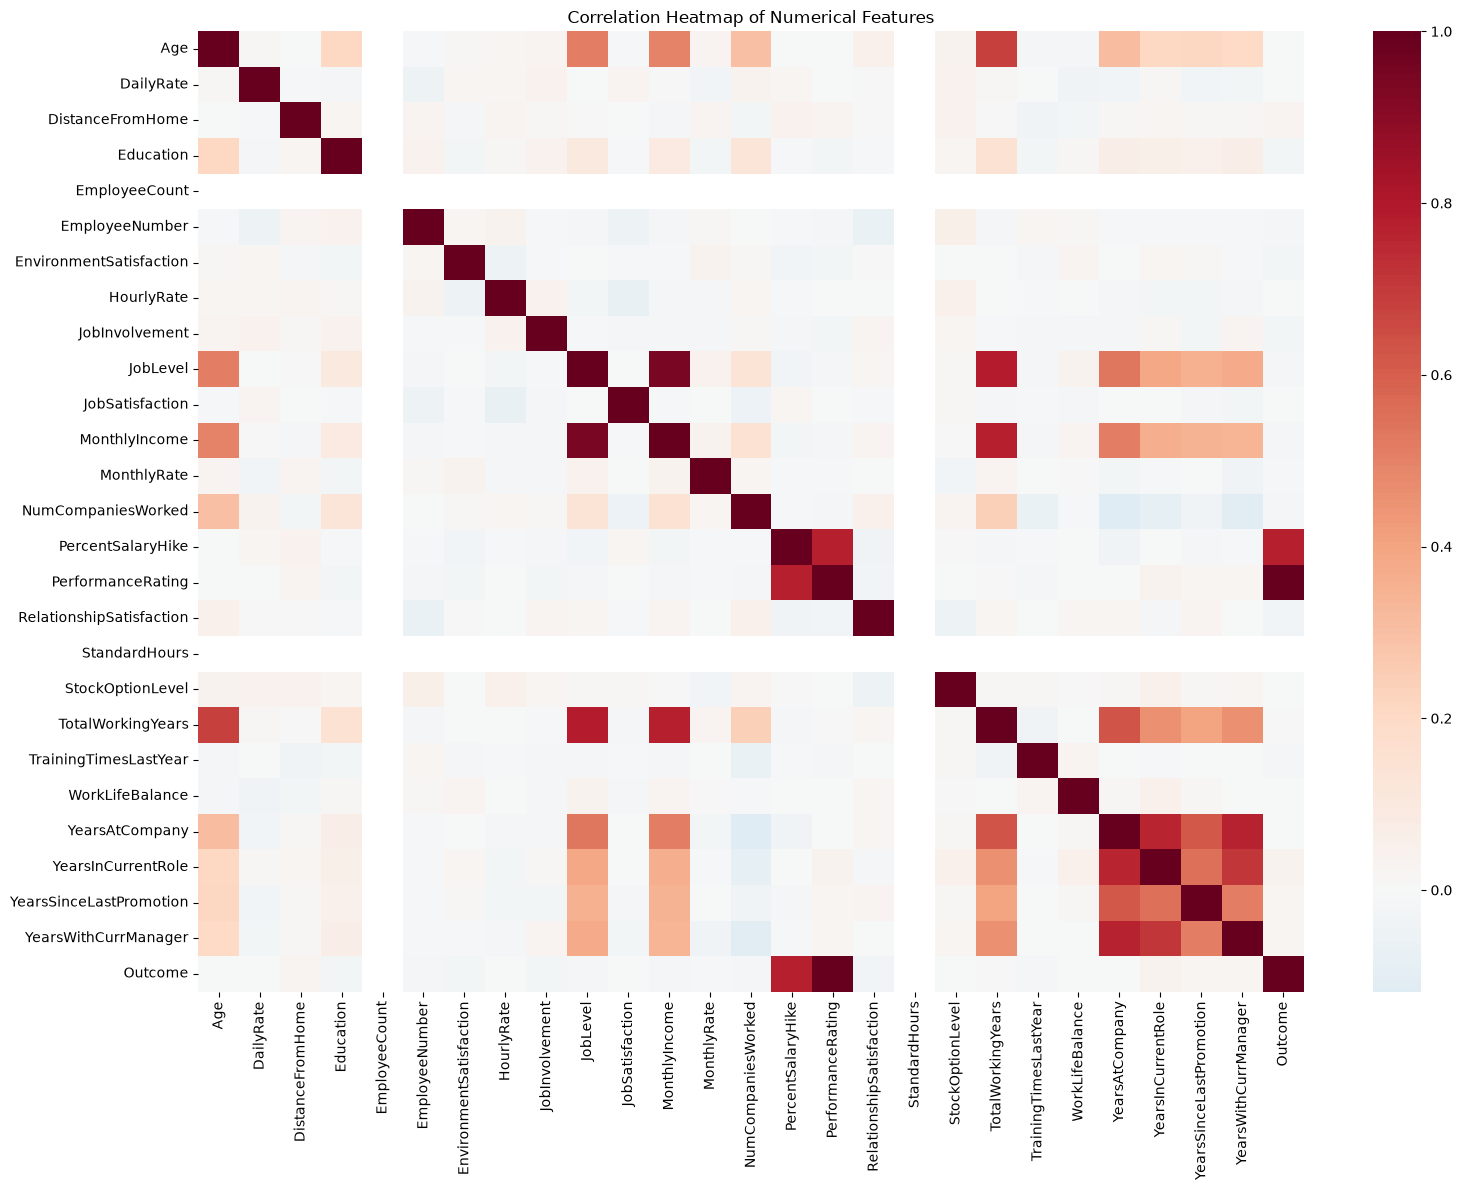

In [12]:
# 7. Correlation Heatmap (numerical features)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(corr, annot=False, cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()


## 4. Data Preprocessing

- Drop irrelevant columns (IDs, constants) and `PercentSalaryHike` (data leakage)
- Impute + Scale numerical features
- Impute + One-Hot Encode categorical features
- 80/20 stratified train-test split
- **Preprocessing is fitted only on training data** to avoid data leakage


In [13]:
# Drop columns
drop_cols = ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours',
             'PercentSalaryHike', 'PerformanceRating']
drop_cols = [c for c in drop_cols if c in df.columns]
df_clean = df.drop(columns=drop_cols)

X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print(f"Numerical features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")


Numerical features (21): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical features (8): ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [14]:
# Build preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit on training data only
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(f"Train set: {X_train_transformed.shape}")
print(f"Test set:  {X_test_transformed.shape}")
print(f"Train target distribution:\n{y_train.value_counts()}")
print(f"Test target distribution:\n{y_test.value_counts()}")


Train set: (1176, 51)
Test set:  (294, 51)
Train target distribution:
Outcome
0    995
1    181
Name: count, dtype: int64
Test target distribution:
Outcome
0    249
1     45
Name: count, dtype: int64


## 5. Model Training

We train three classifiers with `class_weight='balanced'` to handle the class imbalance:
1. **Logistic Regression** — linear baseline
2. **Decision Tree** — interpretable, non-linear
3. **Random Forest** — ensemble, robust


In [15]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=10, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced')
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_transformed, y_train)
    trained_models[name] = model
    print(f"✓ {name} trained.")


✓ Logistic Regression trained.


✓ Decision Tree trained.


✓ Random Forest trained.


## 6. Model Evaluation


In [16]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_transformed)
    y_prob = model.predict_proba(X_test_transformed)[:, 1]
    
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    roc  = roc_auc_score(y_test, y_prob)
    
    results.append({'Model': name, 'Accuracy': round(acc, 4),
                    'Precision': round(prec, 4), 'Recall': round(rec, 4),
                    'F1 Score': round(f1, 4), 'ROC-AUC': round(roc, 4)})

results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5034,0.1203,0.3556,0.1798,0.4597
1,Decision Tree,0.6020,0.1250,0.2667,0.1702,0.4907
2,Random Forest,0.8435,0.0000,0.0000,0.0000,0.4900


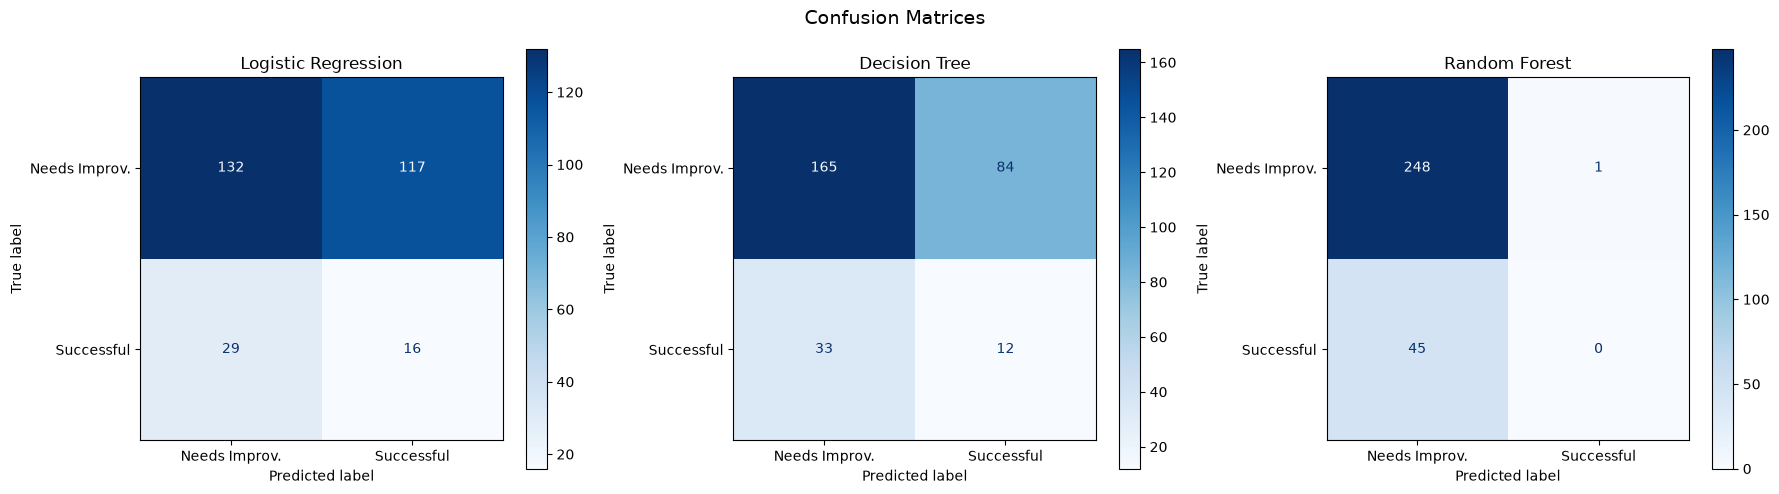

In [17]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_transformed)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap='Blues',
                                            display_labels=['Needs Improv.', 'Successful'])
    ax.set_title(f'{name}')
plt.suptitle('Confusion Matrices', fontsize=14)
plt.tight_layout()
plt.show()


In [18]:
# Detailed classification reports
for name, model in trained_models.items():
    y_pred = model.predict(X_test_transformed)
    print(f"\n{'='*50}")
    print(f"{name}")
    print('='*50)
    print(classification_report(y_test, y_pred,
          target_names=['Needs Improvement', 'Successful'], zero_division=0))



Logistic Regression
                   precision    recall  f1-score   support

Needs Improvement       0.82      0.53      0.64       249
       Successful       0.12      0.36      0.18        45

         accuracy                           0.50       294
        macro avg       0.47      0.44      0.41       294
     weighted avg       0.71      0.50      0.57       294


Decision Tree
                   precision    recall  f1-score   support

Needs Improvement       0.83      0.66      0.74       249
       Successful       0.12      0.27      0.17        45

         accuracy                           0.60       294
        macro avg       0.48      0.46      0.45       294
     weighted avg       0.72      0.60      0.65       294


Random Forest
                   precision    recall  f1-score   support

Needs Improvement       0.85      1.00      0.92       249
       Successful       0.00      0.00      0.00        45

         accuracy                           0.84       2

## 7. Feature Importance

> **Disclaimer:** Feature importance shows which features were important for the model's predictions.  
> It does **not** prove causation.


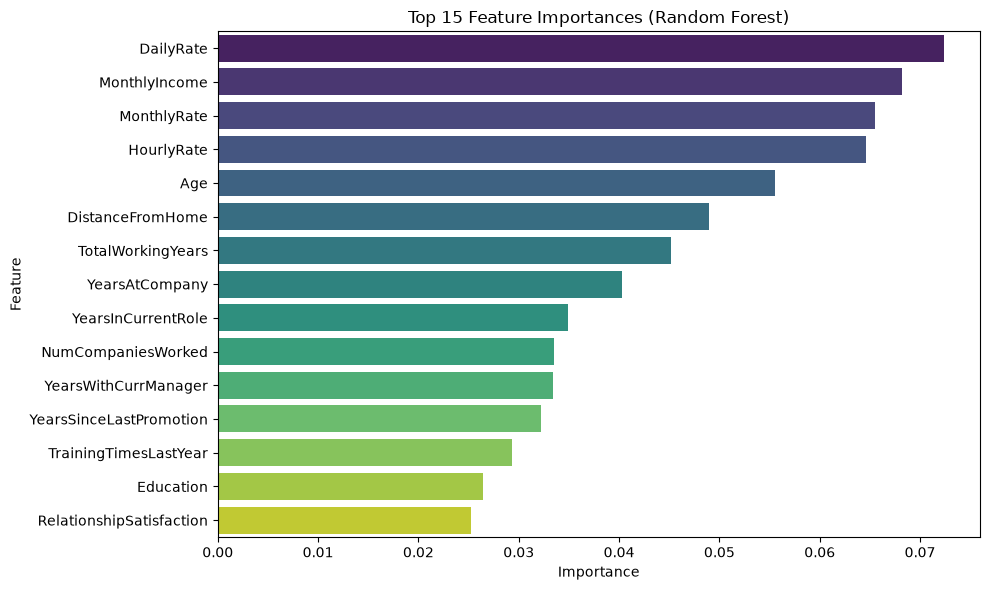

In [19]:
# Random Forest feature importance
rf = trained_models['Random Forest']

# Get feature names after one-hot encoding
ohe_features = preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + ohe_features

importances = rf.feature_importances_
feat_imp = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feat_imp = feat_imp.sort_values('Importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis', ax=ax)
ax.set_title('Top 15 Feature Importances (Random Forest)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()


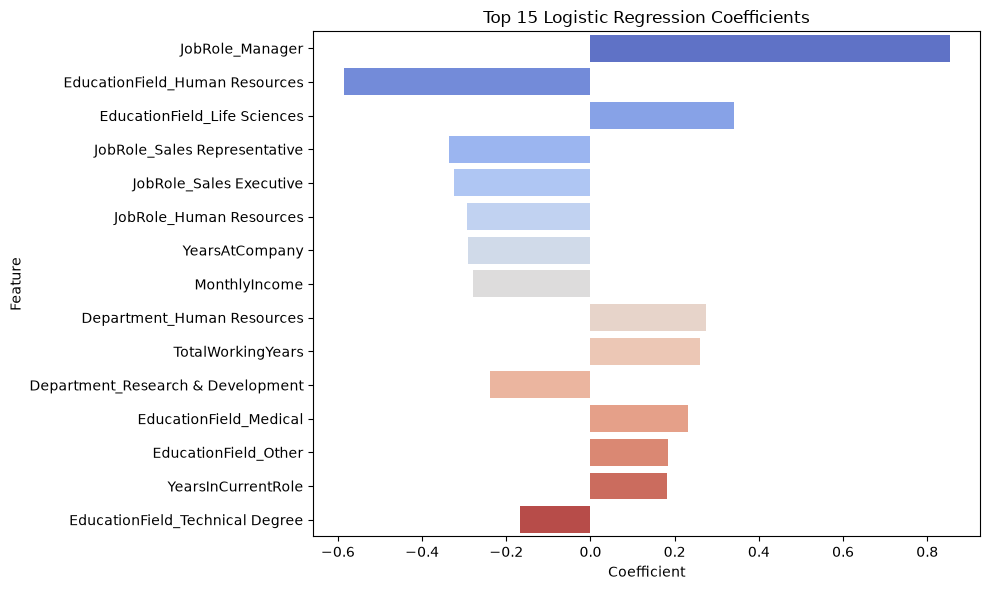

In [20]:
# Logistic Regression coefficients (top features)
lr = trained_models['Logistic Regression']
lr_coefs = pd.DataFrame({'Feature': all_features, 'Coefficient': lr.coef_[0]})
lr_coefs['Abs_Coeff'] = lr_coefs['Coefficient'].abs()
lr_coefs = lr_coefs.sort_values('Abs_Coeff', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=lr_coefs, palette='coolwarm', ax=ax)
ax.set_title('Top 15 Logistic Regression Coefficients')
plt.tight_layout()
plt.show()


## 8. Error Analysis

### Key Observations:
- The dataset is **highly imbalanced** (~85% class 0, ~15% class 1).
- After removing `PercentSalaryHike`, the remaining features have very weak predictive power for `PerformanceRating`.
- **Random Forest** achieves high accuracy by defaulting to the majority class (0 recall for minority).
- **Logistic Regression** (with balanced weights) attempts to capture the minority class but at the cost of many false positives.

### Limitations:
1. The IBM dataset is **synthetic** — patterns may not reflect real organizational behaviour.
2. There is no explicit pre-training / post-training assessment score to measure a direct improvement delta.
3. `TrainingTimesLastYear` records frequency, not quality, duration, or relevance of training.


In [21]:
# Misclassified records analysis (using Logistic Regression as it attempts minority prediction)
lr_model = trained_models['Logistic Regression']
y_pred_lr = lr_model.predict(X_test_transformed)

misclassified = X_test.copy()
misclassified['Actual'] = y_test.values
misclassified['Predicted'] = y_pred_lr

false_positives = misclassified[(misclassified['Actual'] == 0) & (misclassified['Predicted'] == 1)]
false_negatives = misclassified[(misclassified['Actual'] == 1) & (misclassified['Predicted'] == 0)]

print(f"False Positives (predicted Successful, actually Needs Improvement): {len(false_positives)}")
print(f"False Negatives (predicted Needs Improvement, actually Successful): {len(false_negatives)}")
print(f"Total Misclassified: {len(false_positives) + len(false_negatives)} / {len(y_test)}")


False Positives (predicted Successful, actually Needs Improvement): 117
False Negatives (predicted Needs Improvement, actually Successful): 29
Total Misclassified: 146 / 294


## 9. Save Models


In [22]:
import joblib
import os

os.makedirs('../models', exist_ok=True)
joblib.dump(preprocessor, '../models/preprocessing.pkl')
joblib.dump(trained_models['Random Forest'], '../models/final_model.pkl')

for name, model in trained_models.items():
    fname = name.replace(' ', '_').lower() + '_model.pkl'
    joblib.dump(model, f'../models/{fname}')

print("All models and preprocessor saved to ../models/")


All models and preprocessor saved to ../models/


## 10. Conclusion

- The ML pipeline is fully functional and reproducible.
- Due to the synthetic nature of the data and the removal of the leaky `PercentSalaryHike` feature, prediction performance is limited.
- This demonstrates the importance of having high-quality, real-world data with explicit training effectiveness measurements.
- The Streamlit app (`app.py`) provides an interactive dashboard for exploring results and making predictions.
